# Overlap between K562 and GM12878 In-Situ Hi-C jet locations

In [ ]:
import sys
sys.path.append('..')
from utils.plotting import genomic_labels
from func_iou import match_by_iou, unique_pairs
from func_pileup import get_pileups_dynamic_resolution, remove_and_resize_square_stacks, generate_bed_2

import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import bioframe as bf
import pybedtools
from matplotlib_venn import venn2

In [ ]:
# Pileup parameters
data_type = "oe"
expected_stack_size = 100

# Overlap parameters
iou_threshold = 0  # ANY overlap

exp_name_1 = "K562_hic_Rao-2014_ENCFF616PUW_hg38"
exp_name_2 = "GM12878_insitu-hic_4DNFI1UEG1HD"

hic_file_1 = "/nfs/turbo/umms-minjilab/downloaded_data/K562_hic_Rao-2014_ENCFF616PUW_hg38.hic" 
hic_file_2 = "/nfs/turbo/umms-minjilab/downloaded_data/GM12878_insitu-hic_4DNFI1UEG1HD.hic" 

data_name = "Insitu Hi-C K562 vs. Insitu Hi-C GM12878"

resolution = 25000 # 25Kb resolution
normalization = "VC_SQRT"

# Overlap parameter is relative to resolution
buffer_radius = 3 * resolution  

# MIA-JET
output_name = "v2.0.3"
result_type = "q_val_0.5-0.95" 
resolution_miajet = resolution
f_pred_miajet_1_summary = f"/nfs/turbo/umms-minjilab/sionkim/miajet_revision/miajet/output_{output_name}/{exp_name_1}_chr_combined_{genomic_labels(resolution_miajet)}/{exp_name_1}_chr_combined_{result_type}_{genomic_labels(resolution_miajet)}_summary_table.csv"
f_pred_miajet_1_expanded = f"/nfs/turbo/umms-minjilab/sionkim/miajet_revision/miajet/output_{output_name}/{exp_name_1}_chr_combined_{genomic_labels(resolution_miajet)}/{exp_name_1}_chr_combined_{result_type}_{genomic_labels(resolution_miajet)}_expanded_table.csv"

f_pred_miajet_2_summary = f"/nfs/turbo/umms-minjilab/sionkim/miajet_revision/miajet/output_{output_name}/{exp_name_2}_chr_combined_{genomic_labels(resolution_miajet)}/{exp_name_2}_chr_combined_{result_type}_{genomic_labels(resolution_miajet)}_summary_table.csv"
f_pred_miajet_2_expanded = f"/nfs/turbo/umms-minjilab/sionkim/miajet_revision/miajet/output_{output_name}/{exp_name_2}_chr_combined_{genomic_labels(resolution_miajet)}/{exp_name_2}_chr_combined_{result_type}_{genomic_labels(resolution_miajet)}_expanded_table.csv"

# Analysis parameters
save_path = f"/nfs/turbo/umms-minjilab/sionkim/miajet_revision/analysis_{output_name}"

names = [
    "Insitu Hi-C K562",
    "Insitu Hi-C GM12878",
    ]

genomes = [
    "hg38",
    "hg38"
]


miajet_table_list = [
    f_pred_miajet_1_summary,
    f_pred_miajet_2_summary,
]

miajet_position_list = [
    f_pred_miajet_1_expanded,
    f_pred_miajet_2_expanded,
]

hic_file = [hic_file_1, hic_file_2]
names_abbrev = names

In [ ]:
# Load MIA-Jet calls (summary table: one row per jet; expanded table: jet coordinates)
data_name += f" (MIA-Jet {result_type})"

tables = [pd.read_csv(f, comment="#") for f in miajet_table_list]
positions = [pd.read_csv(f, comment="#") for f in miajet_position_list]

table_dict = dict(zip(names, tables))
position_dict = dict(zip(names, positions))

# Chromosomes with at least one jet
common_chroms = set()
for t in tables:
    common_chroms.update(t["chrom"].unique())

## Overlaps

In [ ]:
# COMPUTE OVERLAPS
results = pd.DataFrame(index=names, columns=names, dtype=int).fillna(0)
unique_identifiers = []
name_pairs = []
# fill main diagonal with the total number of jets from each method
for n in names:
    results.loc[n, n] = len(table_dict[n])

for n1, n2 in itertools.combinations(names, 2):

    print("-" * 20)
    print(f"Comparing {n1} and {n2}...")

    genome_wide_overlap = 0
    identifiers = []

    for chrom in common_chroms:

        # IOU method is per-chromosome so filter each table by chromosome
        t1 = position_dict[n1].loc[position_dict[n1]["chrom"] == chrom]
        t2 = position_dict[n2].loc[position_dict[n2]["chrom"] == chrom]

        if t1.empty or t2.empty:
            # if any of the two tables are empty then no need to check for overlaps.. there is none
            continue

        # Compute the pairs of jets in each direction
        pairs12 = match_by_iou(t1, t2, buffer_radius=buffer_radius, iou_threshold=iou_threshold, x_label="x (bp)", y_label="y (bp)")
        pairs21 = match_by_iou(t2, t1, buffer_radius=buffer_radius, iou_threshold=iou_threshold, x_label="x (bp)", y_label="y (bp)")

        # Construct graph and find unique pairs
        pairs = unique_pairs(pairs12, pairs21, method="optimal")

        genome_wide_overlap += len(pairs)
        identifiers += pairs # extend the list

    # Update results table
    results.loc[n1, n2] = genome_wide_overlap
    results.loc[n2, n1] = genome_wide_overlap  # symmetric

    unique_identifiers.append(identifiers)
    name_pairs.append((n1, n2))

print("Genome-wide overlaps:")
print(results)

In [ ]:
def safe_int(x):
    try:
        return int(x)
    except ValueError:
        return x


def split_partitions(n1, n2, pairs):
    """
    Split the jets of n1 and n2 into [n1 only, n1 & n2, n2 only] using the matched (uid1, uid2) pairs.
    Returns the summary tables and the expanded (position) tables of the three partitions.
    The shared partition (n1 & n2) is taken from n1's tables.
    """
    if len(pairs) == 0:
        uid1, uid2 = np.array([]), np.array([])
    else:
        safe_convert = np.vectorize(safe_int)
        uid1 = safe_convert(np.array(pairs)[:, 0])  # unique identifiers from n1
        uid2 = safe_convert(np.array(pairs)[:, 1])  # unique identifiers from n2

    df_A, df_B = table_dict[n1], table_dict[n2]
    df_pos_A, df_pos_B = position_dict[n1], position_dict[n2]

    summary_parts = [
        df_A[~df_A["unique_id"].isin(uid1)].reset_index(drop=True),  # n1 only
        df_A[df_A["unique_id"].isin(uid1)].reset_index(drop=True),   # n1 & n2
        df_B[~df_B["unique_id"].isin(uid2)].reset_index(drop=True),  # n2 only
    ]
    position_parts = [
        df_pos_A[~df_pos_A["unique_id"].isin(uid1)].reset_index(drop=True),
        df_pos_A[df_pos_A["unique_id"].isin(uid1)].reset_index(drop=True),
        df_pos_B[~df_pos_B["unique_id"].isin(uid2)].reset_index(drop=True),
    ]
    return summary_parts, position_parts

### Plot agg

In [ ]:
# AGGREGATE CONTACT MAPS per partition (A only, A & B, B only)
chrom_sizes = {g: bf.fetch_chromsizes(g) for g in set(genomes)}

agg_map_pairs = []
for (n1, n2), pairs in zip(name_pairs, unique_identifiers):
    A_idx, B_idx = names.index(n1), names.index(n2)
    summary_parts, position_parts = split_partitions(n1, n2, pairs)

    # The shared partition is taken from A, so it is piled up on A's Hi-C map
    part_hic = [hic_file[A_idx], hic_file[A_idx], hic_file[B_idx]]
    part_genome = [genomes[A_idx], genomes[A_idx], genomes[B_idx]]

    agg_map = []
    for df_sum, df_pos, f_hic, genome in zip(summary_parts, position_parts, part_hic, part_genome):
        bed_df = generate_bed_2(df_sum, df_pos, eps=500e3, fraction=1.5)

        s, d, r = get_pileups_dynamic_resolution(
            hic_file=f_hic,
            bed_df_in=bed_df,
            expected_stack_size=expected_stack_size,
            chrom_sizes=chrom_sizes[genome],
            chromosomes='all',
            window_range=(None, None),
            data_type=data_type,
            normalization=normalization,
            sort=True,
            verbose=True
        )

        # Remove centromeres and resize square stacks
        s, d = remove_and_resize_square_stacks(s, d, expected_stack_size)

        if data_type == "observed":
            s = np.log10(s + 1) # log transform for visualization

        agg_map.append(np.mean(s, axis=0))  # average over all stacks

    agg_map_pairs.append(agg_map)

agg_map_pairs = np.array(agg_map_pairs)

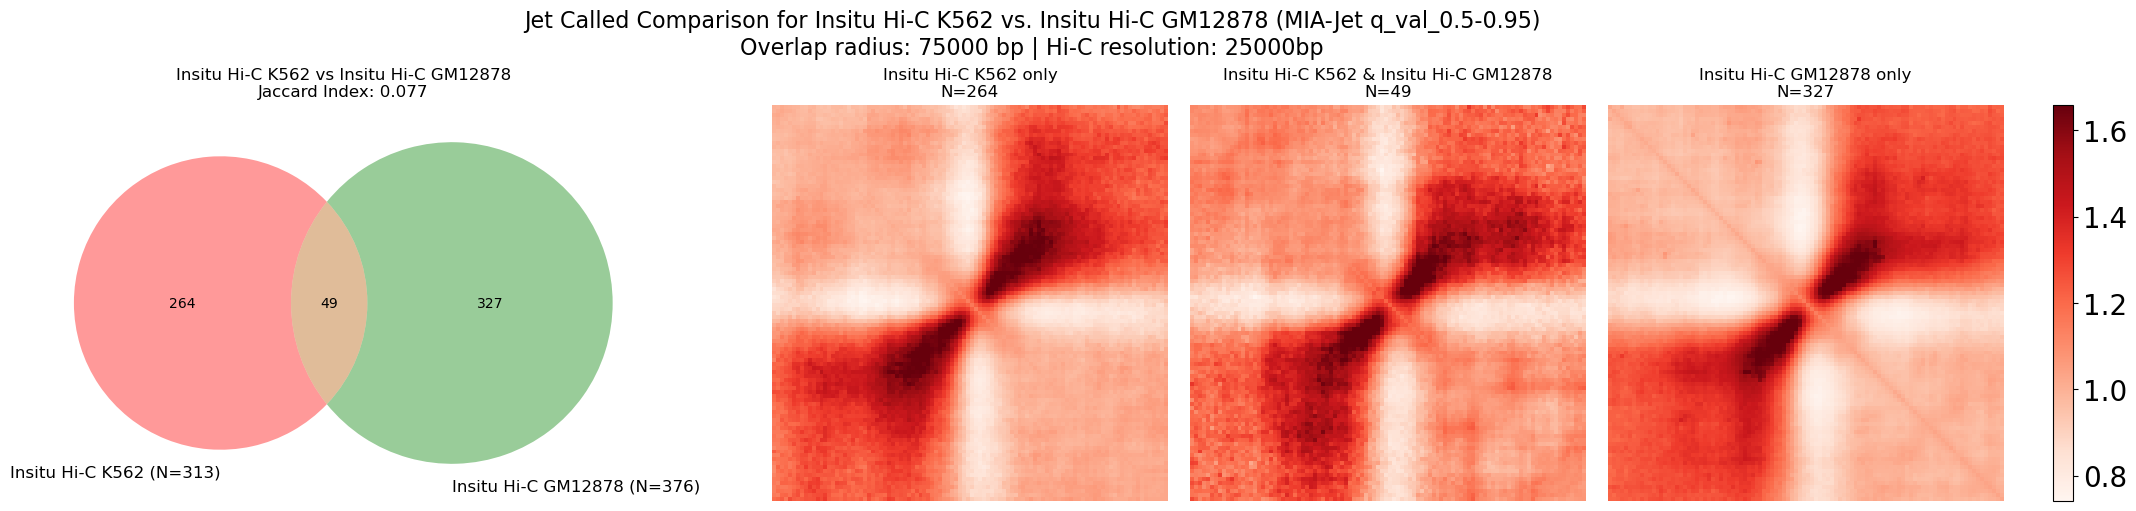

In [12]:
# PLOT VENN DIAGRAM
pairs = list(itertools.combinations(names, 2))
num_pairs = len(pairs)

fig, axes = plt.subplots(num_pairs, 4, figsize=(22, 5*num_pairs), layout='constrained', width_ratios=[2, 1, 1, 1])

for row, (A, B) in enumerate(pairs):
    # compute overlaps as before
    total_A = results.loc[A, A]
    total_B = results.loc[B, B]
    inter = results.loc[A, B]
    only_A = total_A - inter
    only_B = total_B - inter

    # column 0: the Venn
    ax = axes[row]
    venn2(subsets=(int(only_A), int(only_B), int(inter)),
        set_labels=(f"{A} (N={int(total_A)})", f"{B} (N={int(total_B)})"),
        ax=ax)
    ax.set_title(f"{A} vs {B}\nJaccard Index: {inter / (inter + only_A + only_B):.3f}")

    # columns 1–3: the three imshows
    # agg_map_pairs.shape == (n_pairs, 3, H, W)
    A_idx = names.index(A)
    B_idx = names.index(B)
    A_abbrev = names_abbrev[A_idx]
    B_abbrev = names_abbrev[B_idx]
    titles = [f"{A_abbrev} only", f"{A_abbrev} & {B_abbrev}", f"{B_abbrev} only"]
    counts = [int(only_A), int(inter), int(only_B)]
    row_imgs = agg_map_pairs[row]
    row_vmax = max(np.percentile(img, 99) for img in row_imgs)
    for col_idx in range(3):
        ax = axes[col_idx+1]
        img = agg_map_pairs[row, col_idx]
        im = ax.imshow(img, cmap="Reds", interpolation="none", vmax=np.percentile(img, 99))
        ax.set_title(f"{titles[col_idx]}\nN={counts[col_idx]}")
        ax.axis('off')
    cba = fig.colorbar(im, ax=axes[1:], fraction=0.02, pad=0.04)
    cba.ax.tick_params(labelsize=20)



fig.suptitle(f"Jet Called Comparison for {data_name}\nOverlap radius: {int(buffer_radius)} bp | Hi-C resolution: {resolution}bp", fontsize=16)

plt.savefig(f"{save_path}/{data_name}_venn_diagram-agg.png", dpi=300)

plt.show()


## NIPBL ChIP-seq peaks overlapping each jet partition

In [ ]:
f_chrom_sizes = "/nfs/turbo/umms-minjilab/processing/genomes/hg38/hg38.chrom.sizes"

peak_eps = int(resolution)  # slop (bp) added to each side of the jet intervals; same as the Hi-C resolution


def read_peaks_bed(path):
    df = pd.read_csv(path, sep="\t", header=None, comment="#",
                     usecols=[0, 1, 2], names=["chrom", "start", "end"])
    df["start"] = df["start"].astype(np.int64)
    df["end"]   = df["end"].astype(np.int64)
    return df.sort_values(["chrom", "start"]).reset_index(drop=True)


def count_peaks_per_partition(part_pos_df, peak_bt, chrom_sizes_file, eps=0):
    """
    Number of distinct ChIP-seq peaks overlapping a partition's jet intervals.

    part_pos_df : DataFrame with chrom/start/end (a summary table for one partition)
    peak_bt     : pybedtools.BedTool of peaks
    eps         : slop (bp) added to each side of the jet intervals before intersecting
    """
    if part_pos_df is None or len(part_pos_df) == 0:
        return 0

    ivl = part_pos_df[["chrom", "start", "end"]].dropna().copy()
    ivl["start"] = np.floor(ivl["start"]).astype(np.int64)
    ivl["end"]   = np.ceil(ivl["end"]).astype(np.int64)
    ivl['start_new'] = np.minimum(ivl['start'], ivl['end'] - 1)  # ensure start < end
    ivl['end_new'] = np.maximum(ivl['end'], ivl['start'] + 1)    # ensure end > start

    ivl.drop(columns=['start', 'end'], inplace=True)
    ivl.rename(columns={'start_new': 'start', 'end_new': 'end'}, inplace=True)

    ivl = ivl.sort_values(["chrom", "start"]).reset_index(drop=True)

    ivl_bt = pybedtools.BedTool.from_dataframe(ivl)

    if eps and eps > 0:
        ivl_bt = ivl_bt.slop(g=chrom_sizes_file, b=int(eps))

    # u=True -> count each peak once if it overlaps any (slopped) jet interval
    return peak_bt.intersect(ivl_bt, u=True).count()


def count_peaks_per_pair(peak_bts):
    """barchart_pairs[pair][partition][peak_set] = # peaks overlapping that partition's jets"""
    barchart_pairs = []
    for (n1, n2), pairs in zip(name_pairs, unique_identifiers):
        summary_parts, _ = split_partitions(n1, n2, pairs)  # A only, A & B, B only
        barchart_pairs.append([
            [count_peaks_per_partition(sum_df, peak_bt, f_chrom_sizes, eps=peak_eps) for peak_bt in peak_bts]
            for sum_df in summary_parts
        ])
    return barchart_pairs

### GM12878 NIPBL ChIP-seq peaks

In [ ]:
# ChIP-seq peak calls (BED3+ / narrowPeak / broadPeak — only chrom/start/end are used)
bed_files = ["/nfs/turbo/umms-minjilab/processing/results/CHG0030/CHG0030.q30.sorted.nr.spp.z6.broadPeak_merge3kb.bed"]
peak_names = ["GM12878 NIPBL peaks CHG0030"]
peak_names_abrev = ["GM12878 NIPBL"]

peak_bts = [pybedtools.BedTool.from_dataframe(read_peaks_bed(f)) for f in bed_files]
barchart_pairs = count_peaks_per_pair(peak_bts)

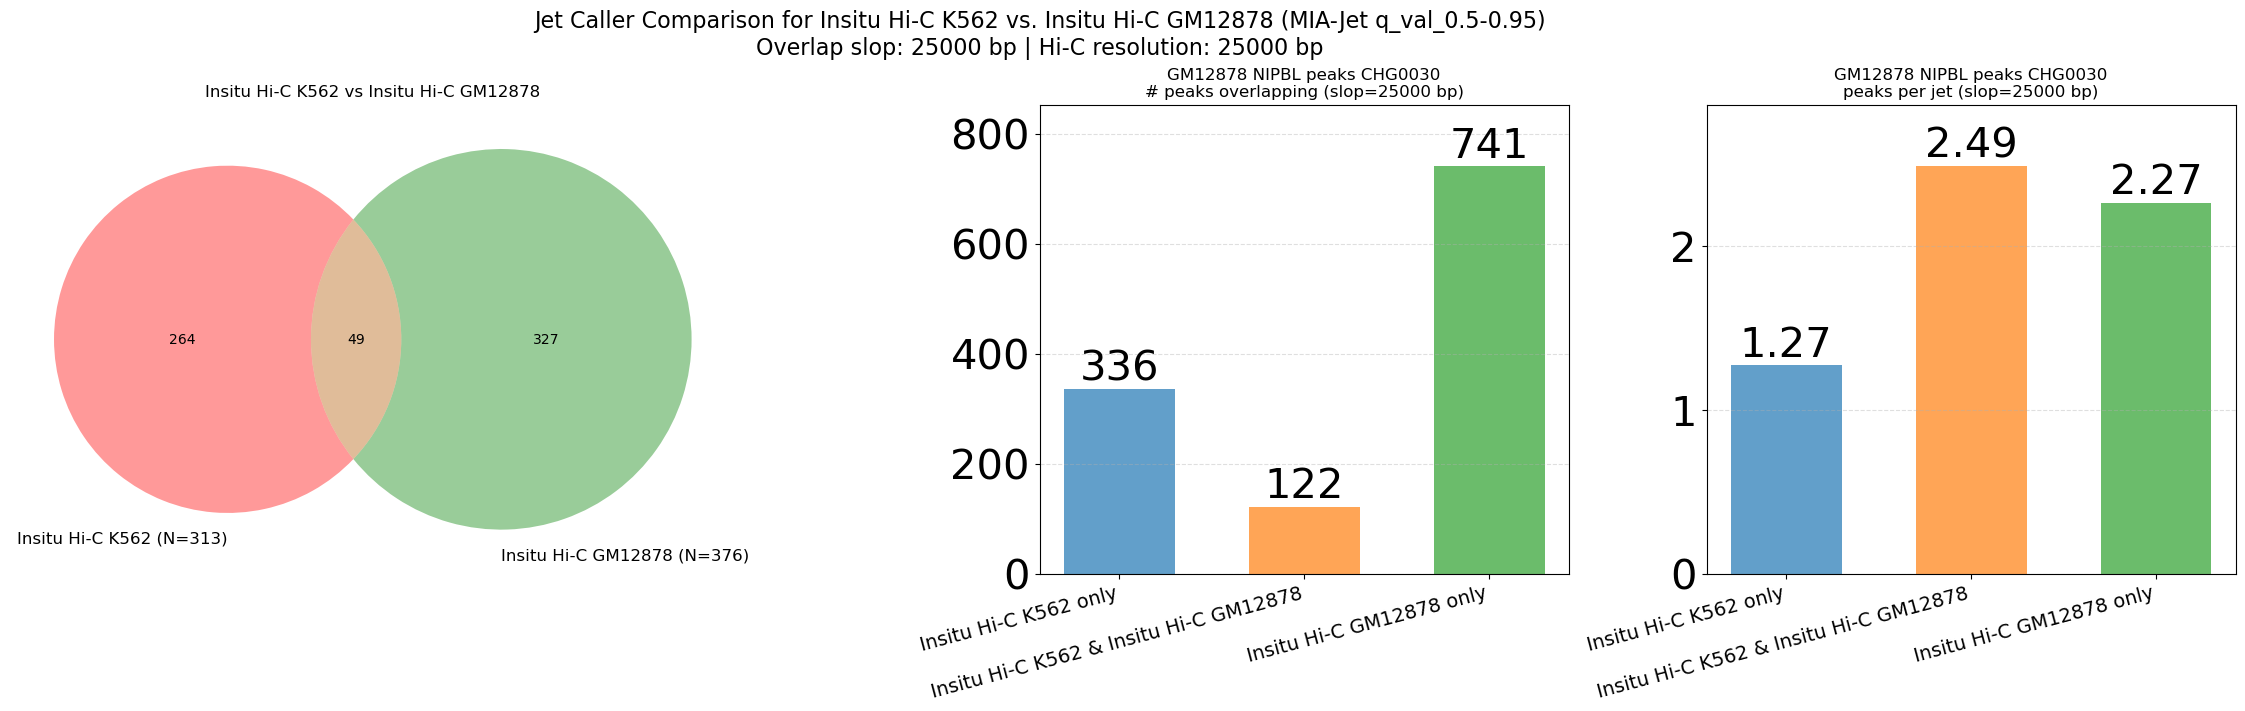

In [77]:
colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

pairs = list(itertools.combinations(names, 2))
num_pairs = len(pairs)
n_exp     = len(bed_files)
n_panels  = 2 * n_exp          # per peak set: raw count + fraction-of-partition

fig, axes = plt.subplots(num_pairs, n_panels + 1,
                         figsize=(8 * (n_panels + 1), 7 * num_pairs),
                         layout='constrained', width_ratios=[2] + [1] * n_panels,
                         squeeze=False)

for row, (A, B) in enumerate(pairs):
    total_A, total_B = results.loc[A, A], results.loc[B, B]
    inter   = results.loc[A, B]
    only_A, only_B = total_A - inter, total_B - inter
    titles  = [f"{A} only", f"{A} & {B}", f"{B} only"]
    counts  = [int(only_A), int(inter), int(only_B)]   # # jets per partition (denominator)

    # 1) Venn in col 0
    ax = axes[row, 0]
    venn2((int(only_A), int(only_B), int(inter)),
          set_labels=(f"{A} (N={int(total_A)})", f"{B} (N={int(total_B)})"), ax=ax)
    ax.set_title(f"{A} vs {B}")

    row_bars = barchart_pairs[row]
    positions_x = np.arange(1, 4)

    # 2) for each peak set -> a count panel and a fraction panel
    for exp_idx in range(n_exp):
        peak_counts = [row_bars[cat][exp_idx] for cat in range(3)]
        fractions   = [(pk / n) if n else 0.0 for pk, n in zip(peak_counts, counts)]

        panels = [
            (peak_counts, "Number of peaks",         "# peaks overlapping", lambda v: f"{int(v)}"),
            (fractions,   "Peaks / partition count", "peaks per jet",       lambda v: f"{v:.2f}"),
        ]

        for k, (vals, ylabel, subtitle, fmt) in enumerate(panels):
            ax = axes[row, 2 * exp_idx + 1 + k]
            ax.bar(positions_x, vals, width=0.6, color=colors[:3], alpha=0.7)
            for x, h in zip(positions_x, vals):
                ax.text(x, h, fmt(h), ha='center', va='bottom', fontsize=30)
            ax.set_xticks(positions_x)
            ax.set_xticklabels(titles, rotation=15, ha='right', fontsize=14)
            ax.set_title(f"{peak_names[exp_idx]}\n{subtitle} (slop={int(peak_eps)} bp)")
            ax.tick_params(axis='y', labelsize=30)
            ax.grid(axis='y', linestyle='--', alpha=0.4)
            ax.set_ylim(0, (max(vals) if any(vals) else 1) * 1.15)

            

fig.suptitle(
    f"Jet Caller Comparison for {data_name}\n"
    f"Overlap slop: {int(peak_eps)} bp | Hi-C resolution: {resolution} bp",
    fontsize=16)

plt.savefig(f"{save_path}/{data_name}_{result_type}_{peak_names_abrev[0]}_venn_diagram-bar.png", dpi=400)

plt.show()

### K562 NIPBL ChIP-seq peaks

In [ ]:
# ChIP-seq peak calls (BED3+ / narrowPeak / broadPeak — only chrom/start/end are used)
bed_files = ["/nfs/turbo/umms-minjilab/downloaded_data/miajet_data_temp/GSM7109956_100PE_GL10CDC5LK562NIPBLR1_L1_peaks.narrowPeak"]
peak_names = ["K562 NIPBL peaks GSM7109956"]
peak_names_abrev = ["K562 NIPBL"]

peak_bts = [pybedtools.BedTool.from_dataframe(read_peaks_bed(f)) for f in bed_files]
barchart_pairs = count_peaks_per_pair(peak_bts)

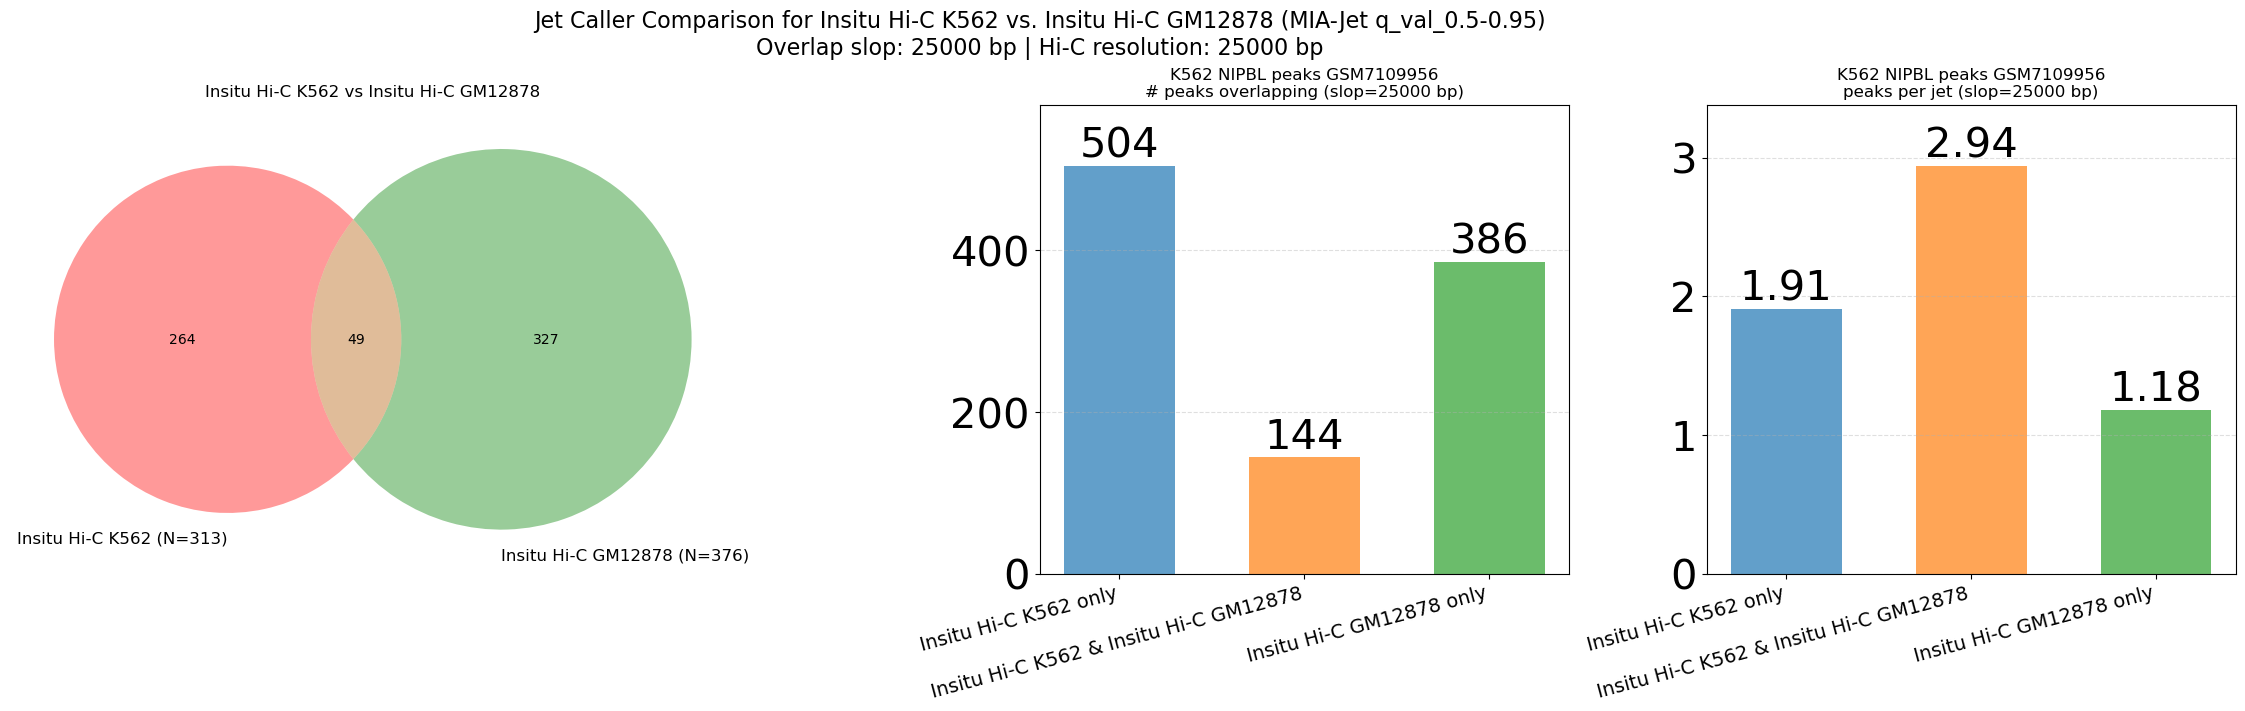

In [83]:
colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

pairs = list(itertools.combinations(names, 2))
num_pairs = len(pairs)
n_exp     = len(bed_files)
n_panels  = 2 * n_exp          # per peak set: raw count + fraction-of-partition

fig, axes = plt.subplots(num_pairs, n_panels + 1,
                         figsize=(8 * (n_panels + 1), 7 * num_pairs),
                         layout='constrained', width_ratios=[2] + [1] * n_panels,
                         squeeze=False)

for row, (A, B) in enumerate(pairs):
    total_A, total_B = results.loc[A, A], results.loc[B, B]
    inter   = results.loc[A, B]
    only_A, only_B = total_A - inter, total_B - inter
    titles  = [f"{A} only", f"{A} & {B}", f"{B} only"]
    counts  = [int(only_A), int(inter), int(only_B)]   # # jets per partition (denominator)

    # 1) Venn in col 0
    ax = axes[row, 0]
    venn2((int(only_A), int(only_B), int(inter)),
          set_labels=(f"{A} (N={int(total_A)})", f"{B} (N={int(total_B)})"), ax=ax)
    ax.set_title(f"{A} vs {B}")

    row_bars = barchart_pairs[row]
    positions_x = np.arange(1, 4)

    # 2) for each peak set -> a count panel and a fraction panel
    for exp_idx in range(n_exp):
        peak_counts = [row_bars[cat][exp_idx] for cat in range(3)]
        fractions   = [(pk / n) if n else 0.0 for pk, n in zip(peak_counts, counts)]

        panels = [
            (peak_counts, "Number of peaks",         "# peaks overlapping", lambda v: f"{int(v)}"),
            (fractions,   "Peaks / partition count", "peaks per jet",       lambda v: f"{v:.2f}"),
        ]

        for k, (vals, ylabel, subtitle, fmt) in enumerate(panels):
            ax = axes[row, 2 * exp_idx + 1 + k]
            ax.bar(positions_x, vals, width=0.6, color=colors[:3], alpha=0.7)
            for x, h in zip(positions_x, vals):
                ax.text(x, h, fmt(h), ha='center', va='bottom', fontsize=30)
            ax.set_xticks(positions_x)
            ax.set_xticklabels(titles, rotation=15, ha='right', fontsize=14)
            ax.set_title(f"{peak_names[exp_idx]}\n{subtitle} (slop={int(peak_eps)} bp)")
            ax.tick_params(axis='y', labelsize=30)
            ax.grid(axis='y', linestyle='--', alpha=0.4)
            ax.set_ylim(0, (max(vals) if any(vals) else 1) * 1.15)

fig.suptitle(
    f"Jet Caller Comparison for {data_name}\n"
    f"Overlap slop: {int(peak_eps)} bp | Hi-C resolution: {resolution} bp",
    fontsize=16)

plt.savefig(f"{save_path}/{data_name}_{result_type}_{peak_names_abrev[0]}_venn_diagram-bar.png", dpi=400)

plt.show()